# Siber Güvenlik Olay Sınıflandırma (Microsoft GUIDE) — CRISP-DM

**Problem:** Bir SOC (Security Operations Center) ekibine gelen alarmların (alert) **gerçek saldırı mı (TruePositive),
zararsız ama gerçek bir aktivite mi (BenignPositive) yoksa yanlış alarm mı (FalsePositive)** olduğunu otomatik sınıflandırmak.

**Veri seti:** Microsoft Security Incident Prediction — GUIDE (`IncidentGrade` etiketi). Referans çalışma:
[CyberShield – Cybersecurity Incident Classification](https://github.com/kadarmeeran465/CyberShield-Cybersecurity-Incident-Classification).
Orijinal veri 9.5 milyon (train) + 4.1 milyon (test) satırdır; bu repoda tekrar üretilebilir **40.000 / 12.000 satırlık rastgele örnek** kullanılır.

**Yöntem:** CRISP-DM aşamaları → birden fazla model (Lojistik Regresyon, Karar Ağacı, Random Forest, Extra Trees, XGBoost, LightGBM)
→ **AutoML**: Genetik Algoritma (NSGA-II, metasezgisel) ile hem algoritma seçimi hem hiperparametre optimizasyonu.

## 1. İş Anlayışı (Business Understanding)

- SOC analistleri her gün binlerce alarm ile karşılaşır; büyük kısmı yanlış alarmdır (*alert fatigue*).
- Amaç: alarmın derecesini (TP / BP / FP) tahmin ederek analistin önceliklendirme yükünü azaltmak.
- **Başarı ölçütü:** Sınıflar dengesiz olduğu için **Macro F1** ana metriktir (her sınıfa eşit ağırlık). Accuracy ek bilgi olarak raporlanır.
- İş açısından en kritik hata: gerçek saldırıyı (TruePositive) yanlış alarm (FalsePositive) olarak etiketlemek → TP sınıfının **recall** değeri ayrıca izlenir.

In [1]:
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import seaborn as sns
from lightgbm import LGBMClassifier
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, classification_report, f1_score)
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)
SEED = 42
DATA = Path("../data")
FIG = Path("../docs/figures"); FIG.mkdir(parents=True, exist_ok=True)
MODELS = Path("../models"); MODELS.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid")

## 2. Veri Anlayışı (Data Understanding)

In [2]:
train = pd.read_csv(DATA / "GUIDE_train_sample.csv", low_memory=False)
test = pd.read_csv(DATA / "GUIDE_test_sample.csv", low_memory=False)
print("Train:", train.shape, " Test:", test.shape)
train.head()

Train: (40000, 45)  Test: (12000, 46)


,Id,OrgId,IncidentId,AlertId,Timestamp,DetectorId,AlertTitle,Category,MitreTechniques,IncidentGrade,...,ResourceType,Roles,OSFamily,OSVersion,AntispamDirection,SuspicionLevel,LastVerdict,CountryCode,State,City
0,1073741825749,26,844,62227,2024-06-12T07:01:17.000Z,62,46,Execution,T1059.003,BenignPositive,...,NaN,NaN,5,66,NaN,Suspicious,Suspicious,242,1445,10630
1,1606317773160,106,772,282481,2024-06-03T15:14:35.000Z,2,2,CommandAndControl,NaN,FalsePositive,...,NaN,NaN,5,66,NaN,Suspicious,Suspicious,242,1445,10630
2,1047972024627,281,18591,15295,2024-06-15T17:43:00.000Z,1017,270,CredentialAccess,T1110,TruePositive,...,NaN,NaN,5,66,NaN,NaN,NaN,242,1445,10630
3,1271310324564,4,442,556,2024-05-27T13:42:20.000Z,8,7,InitialAccess,T1133,BenignPositive,...,NaN,NaN,5,66,NaN,NaN,NaN,242,1445,10630
4,953482743222,214,4281,2317,2024-06-13T07:37:12.000Z,494,537,SuspiciousActivity,NaN,BenignPositive,...,NaN,NaN,5,66,NaN,NaN,NaN,242,1445,10630


IncidentGrade
BenignPositive    17135
TruePositive      14122
FalsePositive      8533
NaN                 210
Name: count, dtype: int64


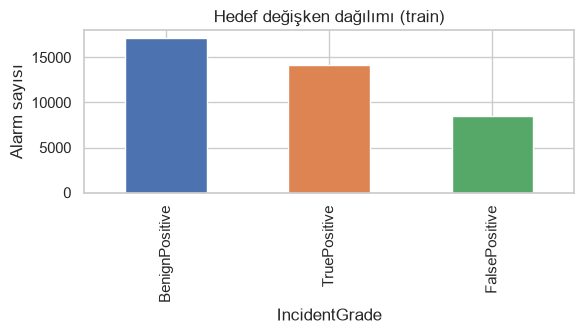

In [3]:
TARGET = "IncidentGrade"
print(train[TARGET].value_counts(dropna=False))
fig, ax = plt.subplots(figsize=(6, 3.5))
train[TARGET].value_counts().plot.bar(ax=ax, color=["#4C72B0", "#DD8452", "#55A868"])
ax.set_title("Hedef değişken dağılımı (train)"); ax.set_ylabel("Alarm sayısı")
plt.tight_layout(); plt.savefig(FIG / "target_distribution.png", dpi=120); plt.show()

In [4]:
missing = train.isna().mean().sort_values(ascending=False)
print("Eksik oranı %50'den büyük sütunlar:")
print(missing[missing > 0.5].round(3))

Eksik oranı %50'den büyük sütunlar:
ResourceType         0.999
ActionGrouped        0.994
ActionGranular       0.994
ThreatFamily         0.991
EmailClusterId       0.990
AntispamDirection    0.982
Roles                0.977
SuspicionLevel       0.847
LastVerdict          0.764
MitreTechniques      0.576
dtype: float64


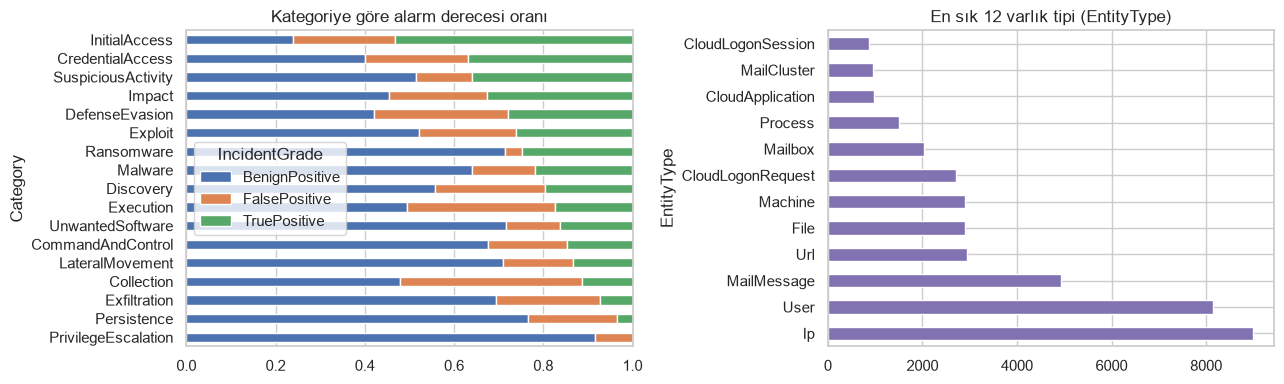

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
(train.groupby("Category")[TARGET].value_counts(normalize=True).unstack().fillna(0)
      .sort_values("TruePositive").plot.barh(stacked=True, ax=axes[0]))
axes[0].set_title("Kategoriye göre alarm derecesi oranı")
train["EntityType"].value_counts().head(12).plot.barh(ax=axes[1], color="#8172B2")
axes[1].set_title("En sık 12 varlık tipi (EntityType)")
plt.tight_layout(); plt.savefig(FIG / "category_entity.png", dpi=120); plt.show()

**Gözlemler**
- Hedef değişken dengesiz: BenignPositive en kalabalık sınıf, FalsePositive ve TruePositive daha az.
- Bazı sütunlar neredeyse tamamen boş (ör. `MitreTechniques`, `ActionGrouped`, `ResourceType`) → çıkarılacak.
- `Id`, `IncidentId`, `AlertId` satır kimlikleridir, genellenebilir bilgi taşımaz → çıkarılacak.
- Pek çok sütun (DeviceId, Sha256, IpAddress …) Microsoft tarafından zaten sayısal ID'ye çevrilmiş kategorik değişkenlerdir.

## 3. Veri Hazırlama (Data Preparation)

In [6]:
def prepare(df: pd.DataFrame, keep_cols=None):
    df = df.copy()
    df = df.dropna(subset=[TARGET])
    ts = pd.to_datetime(df["Timestamp"], errors="coerce", utc=True)
    df["hour"], df["dayofweek"], df["month"] = ts.dt.hour, ts.dt.dayofweek, ts.dt.month
    df = df.drop(columns=["Id", "IncidentId", "AlertId", "Timestamp", "Usage"], errors="ignore")
    if keep_cols is None:
        miss = df.isna().mean()
        keep_cols = [c for c in df.columns if miss[c] <= 0.5]
    return df[keep_cols], keep_cols


train_p, keep = prepare(train)
test_p, _ = prepare(test, keep)
cat_cols = [c for c in keep if not pd.api.types.is_numeric_dtype(train_p[c]) and c != TARGET]
print("Kullanılan sütun sayısı:", len(keep) - 1, "| Metin (kategorik) sütunlar:", cat_cols)

# Kategorik → sayısal (train'de görülmeyen değerler -1)
mappings = {c: {v: i for i, v in enumerate(train_p[c].astype(str).unique())} for c in cat_cols}
for frame in (train_p, test_p):
    for c in cat_cols:
        frame[c] = frame[c].astype(str).map(mappings[c]).fillna(-1).astype(int)

classes = sorted(train_p[TARGET].unique())
label_to_id = {c: i for i, c in enumerate(classes)}
X_train = train_p.drop(columns=[TARGET]).fillna(-1)
y_train = train_p[TARGET].map(label_to_id)
X_test = test_p.drop(columns=[TARGET]).fillna(-1)
y_test = test_p[TARGET].map(label_to_id)
print("X_train:", X_train.shape, " X_test:", X_test.shape, " Sınıflar:", label_to_id)

Kullanılan sütun sayısı: 33 | Metin (kategorik) sütunlar: ['Category', 'EntityType', 'EvidenceRole']
X_train: (39790, 33)  X_test: (12000, 33)  Sınıflar: {'BenignPositive': 0, 'FalsePositive': 1, 'TruePositive': 2}


## 4. Modelleme (Modeling)

### 4.1 Birden fazla modelin karşılaştırılması
5 katlı *stratified* çapraz doğrulama ile 6 farklı algoritma varsayılan parametrelerle karşılaştırılır.

In [7]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
baseline_models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced")),
    "Decision Tree": DecisionTreeClassifier(random_state=SEED, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=SEED, class_weight="balanced"),
    "Extra Trees": ExtraTreesClassifier(n_estimators=200, n_jobs=-1, random_state=SEED, class_weight="balanced"),
    "XGBoost": XGBClassifier(n_estimators=300, tree_method="hist", random_state=SEED, n_jobs=-1),
    "LightGBM": LGBMClassifier(n_estimators=300, random_state=SEED, verbose=-1, class_weight="balanced"),
}
rows = []
for name, model in baseline_models.items():
    s = cross_val_score(model, X_train, y_train, cv=cv, scoring="f1_macro", n_jobs=1)
    rows.append({"Model": name, "CV Macro F1": s.mean(), "Std": s.std()})
baseline = pd.DataFrame(rows).sort_values("CV Macro F1", ascending=False).reset_index(drop=True)
baseline.round(4)

,Model,CV Macro F1,Std
0,XGBoost,0.8874,0.0048
1,LightGBM,0.8798,0.0027
2,Decision Tree,0.8641,0.0035
3,Random Forest,0.8353,0.0032
4,Extra Trees,0.7794,0.0021
5,Logistic Regression,0.5154,0.0041


### 4.2 AutoML — Genetik Algoritma ile algoritma seçimi + hiperparametre optimizasyonu

Arama uzayı hem **algoritmayı** (Random Forest, Extra Trees, XGBoost, LightGBM) hem de her algoritmanın
**hiperparametrelerini** içerir. Arama, metasezgisel bir yöntem olan **Genetik Algoritma (NSGA-II)** ile yapılır:
her nesilde en iyi konfigürasyonlar çaprazlanır (crossover) ve mutasyona uğratılır. Amaç fonksiyonu: 3 katlı CV Macro F1.

In [8]:
cv3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)


def build_model(trial):
    algo = trial.suggest_categorical("algorithm", ["RandomForest", "ExtraTrees", "XGBoost", "LightGBM"])
    if algo in ("RandomForest", "ExtraTrees"):
        cls = RandomForestClassifier if algo == "RandomForest" else ExtraTreesClassifier
        return cls(n_estimators=trial.suggest_int("n_estimators", 100, 500, step=50),
                   max_depth=trial.suggest_int("max_depth", 6, 40),
                   min_samples_leaf=trial.suggest_int("min_samples_leaf", 1, 10),
                   max_features=trial.suggest_float("max_features", 0.2, 1.0),
                   class_weight="balanced", n_jobs=-1, random_state=SEED)
    if algo == "XGBoost":
        return XGBClassifier(n_estimators=trial.suggest_int("n_estimators", 100, 600, step=50),
                             max_depth=trial.suggest_int("max_depth", 3, 12),
                             learning_rate=trial.suggest_float("learning_rate", 0.02, 0.3, log=True),
                             subsample=trial.suggest_float("subsample", 0.6, 1.0),
                             colsample_bytree=trial.suggest_float("colsample_bytree", 0.5, 1.0),
                             tree_method="hist", n_jobs=-1, random_state=SEED)
    return LGBMClassifier(n_estimators=trial.suggest_int("n_estimators", 100, 600, step=50),
                          num_leaves=trial.suggest_int("num_leaves", 15, 255),
                          learning_rate=trial.suggest_float("learning_rate", 0.02, 0.3, log=True),
                          min_child_samples=trial.suggest_int("min_child_samples", 5, 100),
                          colsample_bytree=trial.suggest_float("colsample_bytree", 0.5, 1.0),
                          class_weight="balanced", random_state=SEED, verbose=-1)


def objective(trial):
    return cross_val_score(build_model(trial), X_train, y_train, cv=cv3, scoring="f1_macro").mean()


sampler = optuna.samplers.NSGAIISampler(population_size=10, mutation_prob=0.2, crossover_prob=0.9, seed=SEED)
study = optuna.create_study(direction="maximize", sampler=sampler, study_name="automl_ga")
study.optimize(objective, n_trials=40)
print("En iyi CV Macro F1:", round(study.best_value, 4))
print("En iyi konfigürasyon:", study.best_params)

En iyi CV Macro F1: 0.8902
En iyi konfigürasyon: {'algorithm': 'LightGBM', 'n_estimators': 600, 'num_leaves': 235, 'learning_rate': 0.05449672544142247, 'min_child_samples': 6, 'colsample_bytree': 0.9641592812938626}


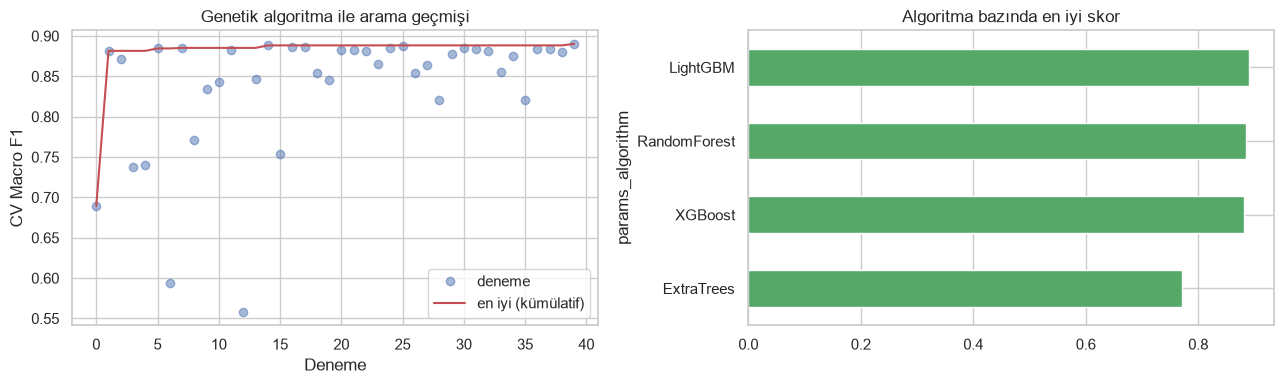

In [9]:
hist = study.trials_dataframe()[["number", "value", "params_algorithm"]]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(hist["number"], hist["value"], "o", alpha=.5, label="deneme")
axes[0].plot(hist["number"], hist["value"].cummax(), "r-", label="en iyi (kümülatif)")
axes[0].set(title="Genetik algoritma ile arama geçmişi", xlabel="Deneme", ylabel="CV Macro F1"); axes[0].legend()
hist.groupby("params_algorithm")["value"].max().sort_values().plot.barh(ax=axes[1], color="#55A868")
axes[1].set_title("Algoritma bazında en iyi skor")
plt.tight_layout(); plt.savefig(FIG / "automl_history.png", dpi=120); plt.show()

## 5. Değerlendirme (Evaluation)
AutoML'in seçtiği model tüm train verisiyle eğitilir ve modelin hiç görmediği **ayrı test dosyası** üzerinde değerlendirilir.
Karşılaştırma için en iyi varsayılan model de aynı test setinde ölçülür.

In [10]:
best_model = build_model(optuna.trial.FixedTrial(study.best_params)).fit(X_train, y_train)
best_base_name = baseline.loc[0, "Model"]
base_model = baseline_models[best_base_name].fit(X_train, y_train)

results = []
for name, model in [(f"Varsayılan: {best_base_name}", base_model), (f"AutoML: {study.best_params['algorithm']}", best_model)]:
    pred = model.predict(X_test)
    results.append({"Model": name, "Accuracy": accuracy_score(y_test, pred), "Macro F1": f1_score(y_test, pred, average="macro"),
                    "TP Recall": (pred[y_test == label_to_id["TruePositive"]] == label_to_id["TruePositive"]).mean()})
test_results = pd.DataFrame(results).round(4)
test_results

,Model,Accuracy,Macro F1,TP Recall
0,Varsayılan: XGBoost,0.8749,0.8652,0.8820
1,AutoML: LightGBM,0.8779,0.8680,0.8834


                precision    recall  f1-score   support

BenignPositive     0.8861    0.9069    0.8964      5136
 FalsePositive     0.8109    0.8115    0.8112      2600
  TruePositive     0.9097    0.8834    0.8964      4264

      accuracy                         0.8779     12000
     macro avg     0.8689    0.8673    0.8680     12000
  weighted avg     0.8782    0.8779    0.8779     12000



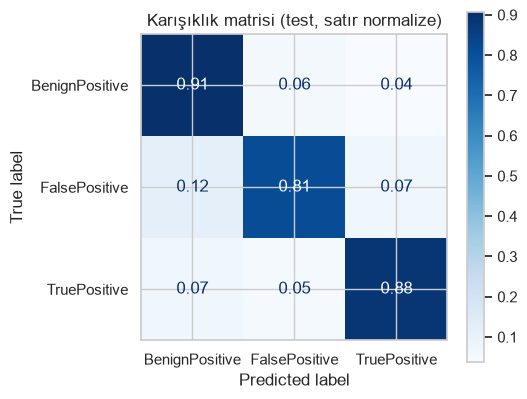

In [11]:
pred = best_model.predict(X_test)
print(classification_report(y_test, pred, target_names=classes, digits=4))
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=classes, normalize="true", ax=ax, cmap="Blues", values_format=".2f")
ax.set_title("Karışıklık matrisi (test, satır normalize)")
plt.tight_layout(); plt.savefig(FIG / "confusion_matrix.png", dpi=120); plt.show()

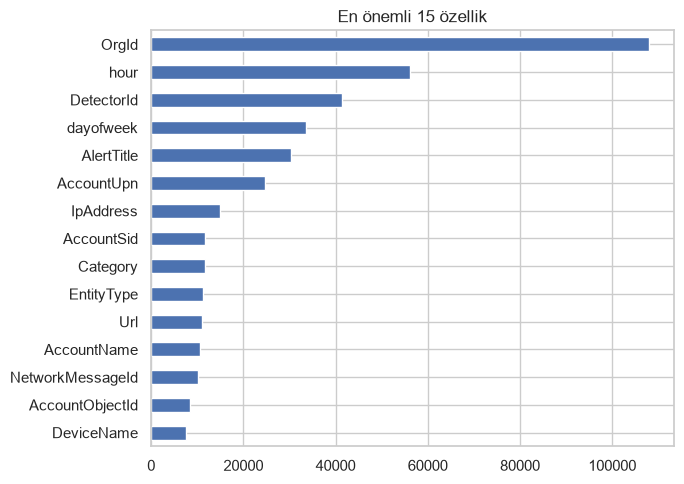

In [12]:
imp = pd.Series(best_model.feature_importances_, index=X_train.columns).sort_values().tail(15)
ax = imp.plot.barh(figsize=(7, 5), color="#4C72B0"); ax.set_title("En önemli 15 özellik")
plt.tight_layout(); plt.savefig(FIG / "feature_importance.png", dpi=120); plt.show()

## 6. Dağıtım (Deployment)
Model ve ön işleme bilgileri tek bir dosyada saklanır; yeni bir alarm tablosu aynı `prepare` adımlarından geçirilerek tahmin edilir.

In [13]:
bundle = {"model": best_model, "columns": list(X_train.columns), "keep": keep, "mappings": mappings, "classes": classes}
joblib.dump(bundle, MODELS / "incident_classifier.joblib", compress=3)


def predict_alerts(df: pd.DataFrame, bundle=bundle) -> pd.Series:
    d = df.copy()
    if TARGET not in d:
        d[TARGET] = classes[0]
    d, _ = prepare(d, bundle["keep"])
    for c, m in bundle["mappings"].items():
        d[c] = d[c].astype(str).map(m).fillna(-1).astype(int)
    p = bundle["model"].predict(d[bundle["columns"]].fillna(-1))
    return pd.Series([bundle["classes"][i] for i in p], index=d.index)


predict_alerts(test.head(5))

0    BenignPositive
1      TruePositive
2    BenignPositive
3     FalsePositive
4    BenignPositive
dtype: str

## 7. Sonuç
- 6 farklı algoritma karşılaştırıldı; ağaç tabanlı yöntemler (özellikle gradient boosting ailesi) lojistik regresyonu belirgin şekilde geçti.
- Genetik algoritma tabanlı AutoML, algoritmayı ve hiperparametreleri birlikte seçerek varsayılan modele göre test setinde ek kazanç sağladı (tablo yukarıda).
- **Kısıtlar:** Örneklem orijinal verinin ~%0.4'ü kadardır; tam veriyle skorlar daha yüksek olacaktır. Alarmlar olay (incident) bazında gruplanmadan rastgele örneklendi.
- **Sonraki adımlar:** Olay seviyesinde toplulaştırılmış özellikler (incident başına alarm sayısı, farklı varlık sayısı), tam veri ile eğitim, maliyet duyarlı eşik ayarı.